# 03 — Pré-treinamento da CNN 2D (MIMII, ventiladores, 6 dB)

Pré-treinamento do ramo acústico (seções 3.3.2 e 7.3):

* **Entrada:** espectrograma log-mel 98 × 40, padronizado com média e desvio do treino.
* **Arquitetura:** três blocos convolucionais (8, 16 e 32 filtros 3 × 3), global average pooling, densa de 16 unidades e saída **binária** (normal ou anômalo), que será substituída pela saída de quatro níveis no fine-tuning.
* **Treino:** entropia cruzada ponderada pelo inverso da frequência das classes, Adam com taxa de 10⁻³, lotes de 32, até 100 épocas, parada antecipada após 10 épocas sem melhora da perda de validação.
* **Repetição:** **cinco sementes**; o notebook reporta média e desvio-padrão.
* **Implantação:** quantização pós-treinamento **int8** (entradas e saídas), calibrada com **100 amostras** do treino, avaliação da versão int8 contra a float32 e geração do vetor C com **xxd**.

**Ambiente:** Ambiente de execução → Alterar tipo → **GPU T4**.

In [1]:
# 1. Ambiente, versões e dados
import sys, os, json, platform, numpy as np, tensorflow as tf
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| Keras", tf.keras.__version__ if hasattr(tf.keras, "__version__") else "")
print("GPU:", tf.config.list_physical_devices("GPU"))
from google.colab import drive
drive.mount("/content/drive")

DADOS = "/content/drive/MyDrive/dissertacao_tinyml/mimii_fan_6db"
SAIDA = "/content/drive/MyDrive/dissertacao_tinyml/modelos/cnn"
os.makedirs(SAIDA, exist_ok=True)
params = json.load(open(f"{DADOS}/params_espectrograma.json"))
MEDIA, DESVIO = params["normalizacao"]["media"], params["normalizacao"]["desvio"]

def carregar(p):
    d = np.load(f"{DADOS}/{p}.npz")
    X = ((d["X"].astype(np.float32) - MEDIA) / DESVIO)[..., None]   # (n, 98, 40, 1)
    return X, d["y"].astype(np.int32), d["grupo"]
Xtr, ytr, gtr = carregar("treino"); Xva, yva, gva = carregar("validacao"); Xte, yte, gte = carregar("teste")
for n, y in [("treino", ytr), ("validação", yva), ("teste", yte)]:
    print(f"{n:10s} n={len(y):6d}  normal={int((y==0).sum())}  anômalo={int((y==1).sum())}")

Python 3.13.15 | TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
treino     n= 38850  normal=28520  anômalo=10330
validação  n=  8320  normal=6110  anômalo=2210
teste      n=  8330  normal=6120  anômalo=2210


In [2]:
# 2. Modelo e configuração de treino
HP = {"filtros": [8, 16, 32], "densa": 16, "lr": 1e-3, "lote": 32, "epocas": 100, "paciencia": 10}
SEMENTES = [0, 1, 2, 3, 4]

def criar_cnn(n_classes=2, filtros=HP["filtros"], densa=HP["densa"]):
    ent = tf.keras.Input(shape=Xtr.shape[1:], name="logmel")
    x = ent
    for i, f in enumerate(filtros):
        x = tf.keras.layers.Conv2D(f, 3, padding="same", activation="relu", name=f"conv{i+1}")(x)
        if i < len(filtros) - 1:
            x = tf.keras.layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dense(densa, activation="relu", name="densa")(x)
    sai = tf.keras.layers.Dense(n_classes, activation="softmax", name="saida")(x)
    return tf.keras.Model(ent, sai, name="cnn2d")

# Pesos pelo inverso da frequência das classes no treino
cont = np.bincount(ytr); PESOS = {c: len(ytr) / (len(cont) * n) for c, n in enumerate(cont)}
print("Pesos das classes:", {k: round(v, 3) for k, v in PESOS.items()})
criar_cnn().summary()

Pesos das classes: {0: np.float64(0.681), 1: np.float64(1.88)}


Model: "cnn2d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ logmel (InputLayer)             │ (None, 98, 40, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 98, 40, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 49, 20, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 49, 20, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 24, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 24, 10, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,450 (25.20 KB)

 Trainable params: 6,450 (25.20 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# 3. Treino com cinco sementes
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, roc_auc_score, confusion_matrix
import pandas as pd

def metricas(y, prob):
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {"acuracia": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro"),
            "precisao_normal": p[0], "recall_normal": r[0], "f1_normal": f[0],
            "precisao_anomalo": p[1], "recall_anomalo": r[1], "f1_anomalo": f[1],
            "auc": roc_auc_score(y, prob[:, 1])}

def por_clipe(prob, grupo, y):
    """Agregação por clipe de 10 s: média das probabilidades das janelas."""
    df = pd.DataFrame({"g": grupo, "p": prob[:, 1], "y": y}).groupby("g").mean()
    return np.stack([1 - df.p, df.p], 1), df.y.astype(int).values

resultados, historicos = [], {}
for s in SEMENTES:
    tf.keras.utils.set_random_seed(s)
    modelo = criar_cnn()
    modelo.compile(optimizer=tf.keras.optimizers.Adam(HP["lr"]), loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["paciencia"], restore_best_weights=True)
    h = modelo.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=HP["epocas"], batch_size=HP["lote"],
                   class_weight=PESOS, callbacks=[parada], verbose=2)
    historicos[s] = h.history
    prob_va, prob_te = modelo.predict(Xva, verbose=0), modelo.predict(Xte, verbose=0)
    m = {"semente": s, "epocas": len(h.history["loss"]), "f1_macro_validacao": f1_score(yva, prob_va.argmax(1), average="macro")}
    m.update({f"teste_{k}": v for k, v in metricas(yte, prob_te).items()})
    pc, yc = por_clipe(prob_te, gte, yte)
    m.update({f"clipe_{k}": v for k, v in metricas(yc, pc).items()})
    resultados.append(m)
    modelo.save(f"{SAIDA}/cnn_semente{s}.keras")
    print(f"semente {s}: F1 macro (teste) = {m['teste_f1_macro']:.4f} | AUC = {m['teste_auc']:.4f}")

res = pd.DataFrame(resultados).set_index("semente")
res.to_csv(f"{SAIDA}/resultados_sementes.csv")
resumo = res.agg(["mean", "std"]).T
display(resumo.round(4)); resumo.to_csv(f"{SAIDA}/resultados_media_desvio.csv")

Epoch 1/100
1215/1215 - 15s - 12ms/step - accuracy: 0.7796 - loss: 0.4355 - val_accuracy: 0.9507 - val_loss: 0.1423
Epoch 2/100
1215/1215 - 5s - 4ms/step - accuracy: 0.9578 - loss: 0.1125 - val_accuracy: 0.9671 - val_loss: 0.0865
Epoch 3/100
1215/1215 - 5s - 4ms/step - accuracy: 0.9715 - loss: 0.0767 - val_accuracy: 0.9769 - val_loss: 0.0658
Epoch 4/100
1215/1215 - 5s - 4ms/step - accuracy: 0.9763 - loss: 0.0633 - val_accuracy: 0.9775 - val_loss: 0.0640
Epoch 5/100
1215/1215 - 5s - 4ms/step - accuracy: 0.9799 - loss: 0.0559 - val_accuracy: 0.9782 - val_loss: 0.0618
Epoch 6/100
1215/1215 - 5s - 4ms/step - accuracy: 0.9816 - loss: 0.0494 - val_accuracy: 0.9812 - val_loss: 0.0557
Epoch 7/100
1215/1215 - 5s - 4ms/step - accuracy: 0.9843 - loss: 0.0432 - val_accuracy: 0.9849 - val_loss: 0.0493
Epoch 8/100
1215/1215 - 6s - 5ms/step - accuracy: 0.9855 - loss: 0.0396 - val_accuracy: 0.9861 - val_loss: 0.0468
Epoch 9/100
1215/1215 - 10s - 8ms/step - accuracy: 0.9867 - loss: 0.0370 - val_accurac

,mean,std
epocas,36.0000,8.0000
f1_macro_validacao,0.9903,0.0015
teste_acuracia,0.9925,0.0017
teste_f1_macro,0.9904,0.0022
teste_precisao_normal,0.9954,0.0015
teste_recall_normal,0.9944,0.0029
teste_f1_normal,0.9949,0.0012
teste_precisao_anomalo,0.9847,0.0078
teste_recall_anomalo,0.9872,0.0041
teste_f1_anomalo,0.9860,0.0032


In [15]:
# 3b. Robustez: deixar uma máquina de fora (treino em 3 máquinas, teste na 4ª), semente 0
inv_csv = pd.read_csv(f"{DADOS}/particao_por_gravacao.csv")
maq = inv_csv["maquina"].values
X_all = np.concatenate([Xtr, Xva, Xte]); y_all = np.concatenate([ytr, yva, yte])
g_all = np.concatenate([gtr, gva, gte]); m_all = maq[g_all]
lomo = []
for m in sorted(set(maq)):
    tf.keras.utils.set_random_seed(0)
    te = m_all == m
    grupos = np.unique(g_all[~te])
    va_g = np.random.default_rng(0).choice(grupos, int(0.15 * len(grupos)), replace=False)
    va = np.isin(g_all, va_g) & ~te; tr = ~te & ~va
    cont = np.bincount(y_all[tr]); pesos = {c: tr.sum() / (2 * n) for c, n in enumerate(cont)}
    mod = criar_cnn()
    mod.compile(optimizer=tf.keras.optimizers.Adam(HP["lr"]), loss="sparse_categorical_crossentropy")
    mod.fit(X_all[tr], y_all[tr], validation_data=(X_all[va], y_all[va]), epochs=HP["epocas"],
            batch_size=HP["lote"], class_weight=pesos, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["paciencia"], restore_best_weights=True)])
    r = metricas(y_all[te], mod.predict(X_all[te], verbose=0)); r["maquina_teste"] = m; lomo.append(r)
    print(f"{m}: F1 macro = {r['f1_macro']:.4f} | recall anômalo = {r['recall_anomalo']:.4f} | AUC = {r['auc']:.4f}")
lomo = pd.DataFrame(lomo).set_index("maquina_teste")
display(lomo.round(4)); lomo.to_csv(f"{SAIDA}/robustez_deixar_maquina_fora.csv")
del X_all

id_00: F1 macro = 0.2231 | recall anômalo = 1.0000 | AUC = 0.5027
id_02: F1 macro = 0.6756 | recall anômalo = 0.6554 | AUC = 0.7694
id_04: F1 macro = 0.5124 | recall anômalo = 0.8489 | AUC = 0.7628
id_06: F1 macro = 0.2078 | recall anômalo = 1.0000 | AUC = 0.5000


,acuracia,f1_macro,precisao_normal,recall_normal,f1_normal,precisao_anomalo,recall_anomalo,f1_anomalo,auc
maquina_teste,,,,,,,,,
id_00,0.2871,0.2231,1.0000,0.0001,0.0002,0.2870,1.0000,0.4461,0.5027
id_02,0.7225,0.6756,0.8597,0.7462,0.7989,0.4771,0.6554,0.5522,0.7694
id_04,0.5162,0.5124,0.8881,0.4042,0.5555,0.3243,0.8489,0.4693,0.7628
id_06,0.2624,0.2078,0.0000,0.0000,0.0000,0.2624,1.0000,0.4157,0.5000


In [16]:
# 3c. Deixar uma máquina de fora, com normalização pela linha de base de cada máquina
# Cada máquina é padronizada por filtro mel com média e desvio dos seus próprios sons normais
# de referência (20% dos clipes normais, retirados do teste) — análogo à linha de base de 24 h.
rng = np.random.default_rng(0)
base = np.zeros(len(y_all), bool)
for m in sorted(set(maq)):
    gn = np.unique(g_all[(m_all == m) & (y_all == 0)])
    base |= np.isin(g_all, rng.choice(gn, int(0.2 * len(gn)), replace=False))

Xn = np.concatenate([Xtr, Xva, Xte])[..., 0] * DESVIO + MEDIA     # volta ao log-mel original
for m in sorted(set(maq)):
    sel = m_all == m; ref = sel & base
    mu = Xn[ref].mean(axis=(0, 1)); sd = Xn[ref].std(axis=(0, 1)) + 1e-6   # 40 médias e 40 desvios
    Xn[sel] = (Xn[sel] - mu) / sd
Xn = Xn[..., None]

lomo2 = []
for m in sorted(set(maq)):
    tf.keras.utils.set_random_seed(0)
    te = (m_all == m) & ~base; outros = m_all != m
    grupos = np.unique(g_all[outros])
    va_g = np.random.default_rng(0).choice(grupos, int(0.15 * len(grupos)), replace=False)
    va = np.isin(g_all, va_g) & outros; tr = outros & ~va
    cont = np.bincount(y_all[tr]); pesos = {c: tr.sum() / (2 * n) for c, n in enumerate(cont)}
    mod = criar_cnn()
    mod.compile(optimizer=tf.keras.optimizers.Adam(HP["lr"]), loss="sparse_categorical_crossentropy")
    mod.fit(Xn[tr], y_all[tr], validation_data=(Xn[va], y_all[va]), epochs=HP["epocas"],
            batch_size=HP["lote"], class_weight=pesos, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["paciencia"], restore_best_weights=True)])
    r = metricas(y_all[te], mod.predict(Xn[te], verbose=0)); r["maquina_teste"] = m; lomo2.append(r)
    print(f"{m}: F1 macro = {r['f1_macro']:.4f} | recall anômalo = {r['recall_anomalo']:.4f} | AUC = {r['auc']:.4f}")
lomo2 = pd.DataFrame(lomo2).set_index("maquina_teste")
display(lomo2.round(4)); lomo2.to_csv(f"{SAIDA}/robustez_linha_de_base_por_maquina.csv")
del Xn

id_00: F1 macro = 0.5985 | recall anômalo = 0.2319 | AUC = 0.7894
id_02: F1 macro = 0.8565 | recall anômalo = 0.6563 | AUC = 0.9790
id_04: F1 macro = 0.8444 | recall anômalo = 0.6210 | AUC = 0.9674
id_06: F1 macro = 0.7250 | recall anômalo = 0.8573 | AUC = 0.8757


,acuracia,f1_macro,precisao_normal,recall_normal,f1_normal,precisao_anomalo,recall_anomalo,f1_anomalo,auc
maquina_teste,,,,,,,,,
id_00,0.7321,0.5985,0.7180,0.9837,0.8301,0.8773,0.2319,0.3669,0.7894
id_02,0.8908,0.8565,0.8676,0.9943,0.9266,0.9808,0.6563,0.7864,0.9790
id_04,0.8862,0.8444,0.8622,0.9978,0.9251,0.9917,0.6210,0.7637,0.9674
id_06,0.7371,0.7250,0.9151,0.6836,0.7826,0.5464,0.8573,0.6675,0.8757


Semente escolhida para implantação (maior F1 macro na validação): 4


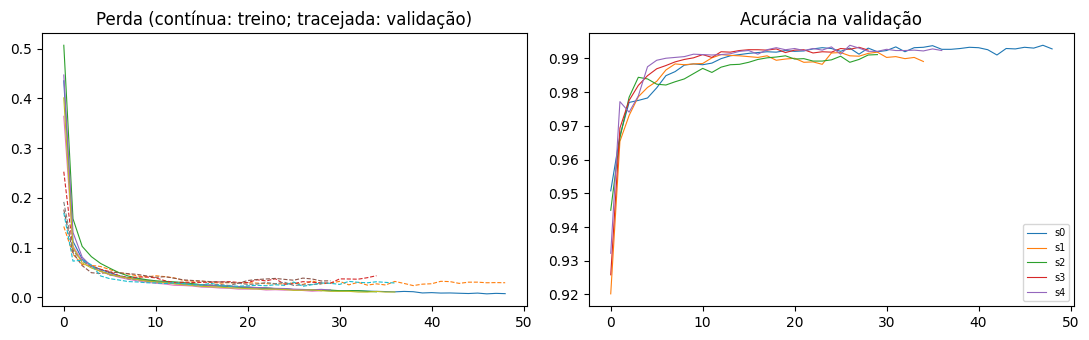

Matriz de confusão (teste, por janela) — linhas: real; colunas: predito [normal, anômalo]
[[6099   21]
 [  32 2178]]


In [4]:
# 4. Curvas de treino e matriz de confusão do modelo escolhido
import matplotlib.pyplot as plt
ESCOLHIDA = int(res["f1_macro_validacao"].idxmax())      # escolha pela validação, nunca pelo teste
print("Semente escolhida para implantação (maior F1 macro na validação):", ESCOLHIDA)
modelo = tf.keras.models.load_model(f"{SAIDA}/cnn_semente{ESCOLHIDA}.keras")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for s, h in historicos.items():
    ax[0].plot(h["loss"], lw=.8, label=f"treino s{s}"); ax[0].plot(h["val_loss"], "--", lw=.8)
    ax[1].plot(h["val_accuracy"], lw=.8, label=f"s{s}")
ax[0].set_title("Perda (contínua: treino; tracejada: validação)"); ax[1].set_title("Acurácia na validação")
ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{SAIDA}/curvas_treino.png", dpi=150); plt.show()

cm = confusion_matrix(yte, modelo.predict(Xte, verbose=0).argmax(1))
print("Matriz de confusão (teste, por janela) — linhas: real; colunas: predito [normal, anômalo]"); print(cm)

In [12]:
# 5. Conversão para TFLite: float32 e int8 (entradas e saídas), calibração com 100 amostras do treino
rng = np.random.default_rng(0)
idx_rep = rng.choice(len(Xtr), 100, replace=False)
def dataset_representativo():
    for i in idx_rep:
        yield [Xtr[i:i+1]]

conv = tf.lite.TFLiteConverter.from_keras_model(modelo)
tfl_f32 = conv.convert()

conv = tf.lite.TFLiteConverter.from_keras_model(modelo)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = dataset_representativo
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
tfl_i8 = conv.convert()

open(f"{SAIDA}/cnn_float32.tflite", "wb").write(tfl_f32)
open(f"{SAIDA}/cnn_int8.tflite", "wb").write(tfl_i8)
kb = lambda b: len(b) / 1024
print(f"float32: {kb(tfl_f32):.1f} KB | int8: {kb(tfl_i8):.1f} KB | redução: {100*(1-len(tfl_i8)/len(tfl_f32)):.1f}%")
print("Parâmetros treináveis:", modelo.count_params())

Saved artifact at '/tmp/tmpwgxdpsvb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40, 1), dtype=tf.float32, name='logmel')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  137876504811024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504814672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504815440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504817936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504814864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504813712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504812944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504815056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876504820240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137876302484432: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifact at '/tmp/

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


float32: 29.1 KB | int8: 12.7 KB | redução: 56.4%
Parâmetros treináveis: 6450


In [13]:
# 6. Avaliação da versão int8 contra a float32 (mesmo conjunto de teste)
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter

def prever_tflite(modelo_bytes, X):
    it = Interpreter(model_content=modelo_bytes); it.allocate_tensors()
    ent, sai = it.get_input_details()[0], it.get_output_details()[0]
    esc_e, zero_e = ent["quantization"]; esc_s, zero_s = sai["quantization"]
    out = np.zeros((len(X), sai["shape"][-1]), np.float32)
    for i in range(len(X)):
        x = X[i:i+1]
        if ent["dtype"] == np.int8:
            x = np.clip(np.round(x / esc_e + zero_e), -128, 127).astype(np.int8)
        it.set_tensor(ent["index"], x); it.invoke()
        y = it.get_tensor(sai["index"]).astype(np.float32)
        out[i] = (y - zero_s) * esc_s if sai["dtype"] == np.int8 else y
    return out

p32 = prever_tflite(tfl_f32, Xte); p8 = prever_tflite(tfl_i8, Xte)
comp = pd.DataFrame({"float32": metricas(yte, p32), "int8": metricas(yte, p8)})
comp["diferença"] = comp["int8"] - comp["float32"]
display(comp.round(4)); comp.to_csv(f"{SAIDA}/float32_vs_int8.csv")
print("Concordância de predições float32 x int8:", f"{100*(p32.argmax(1)==p8.argmax(1)).mean():.2f}%")

it = Interpreter(model_content=tfl_i8); it.allocate_tensors()
q = {"entrada": [float(v) for v in it.get_input_details()[0]["quantization"]],
     "saida": [float(v) for v in it.get_output_details()[0]["quantization"]]}
json.dump({"semente": ESCOLHIDA, "quantizacao": q, "normalizacao": {"media": MEDIA, "desvio": DESVIO}},
          open(f"{SAIDA}/cnn_int8_quantizacao.json", "w"), indent=2)
print("Escala/zero de entrada e saída (o firmware precisa deles):", q)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,float32,int8,diferença
acuracia,0.9936,0.9938,0.0001
f1_macro,0.9918,0.9920,0.0002
precisao_normal,0.9948,0.9946,-0.0002
recall_normal,0.9966,0.9969,0.0003
f1_normal,0.9957,0.9958,0.0001
precisao_anomalo,0.9905,0.9913,0.0009
recall_anomalo,0.9855,0.9851,-0.0005
f1_anomalo,0.9880,0.9882,0.0002
auc,0.9997,0.9989,-0.0008


Concordância de predições float32 x int8: 99.94%
Escala/zero de entrada e saída (o firmware precisa deles): {'entrada': [0.028519157320261, -10.0], 'saida': [0.00390625, -128.0]}


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [14]:
# 7. Vetor C para o firmware (xxd), com alinhamento de 16 bytes exigido pelo TFLite Micro
os.chdir(SAIDA)
!which xxd > /dev/null || apt-get -qq install -y xxd > /dev/null
!xxd -i cnn_int8.tflite > cnn_int8_model.h
h = open("cnn_int8_model.h").read().replace("unsigned char", "alignas(16) const unsigned char", 1)
h = h.replace("unsigned int", "const unsigned int", 1)
open("cnn_int8_model.h", "w").write("// Gerado por xxd -i a partir de cnn_int8.tflite\n" + h)
print(open("cnn_int8_model.h").read()[:300], "...")
print("Tamanho do .h:", os.path.getsize("cnn_int8_model.h") // 1024, "KB")

// Gerado por xxd -i a partir de cnn_int8.tflite
alignas(16) const unsigned char cnn_int8_tflite[] = {
  0x20, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x00, 0x00, 0x00, 0x00,
  0x14, 0x00, 0x20, 0x00, 0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00,
  0x0c, 0x00, 0x00, 0x00, 0x08, 0x00, 0x04, 0x00, ...
Tamanho do .h: 78 KB


## Resultado

Em `dissertacao_tinyml/modelos/cnn/`:

| Arquivo | Uso na dissertação |
|---|---|
| `resultados_sementes.csv`, `resultados_media_desvio.csv` | seção 8 (pré-treinamento): média ± desvio em cinco sementes, por janela e por clipe |
| `curvas_treino.png` | figura de convergência |
| `cnn_float32.tflite`, `cnn_int8.tflite` | Tabela 10 (tamanho antes e após a quantização) |
| `float32_vs_int8.csv` | comparação int8 × float32 (Apêndice B.7) |
| `cnn_int8_model.h`, `cnn_int8_quantizacao.json` | firmware de inferência |

As métricas são do **pré-treinamento binário no MIMII**; elas **não** testam H1 nem H2, que dependem da coleta in situ.